# 4. Perturbation theory: qubit decay and drives

This notebook adds qubit decay ($T_1$) to the two examples of the paper, using the perturbation theory of Sec. VII.

Decay is not an operator-valued Gaussian process. The jump term $\Gamma_1\hat\sigma_-\hat\varrho\,\hat\sigma_+$ moves population from the excited branch $\varrho_{++}$ to the ground branch $\varrho_{--}$, so the state is no longer a single GBCS. We split the Lindbladian in two. One part keeps every branch Gaussian; it includes the damping $-\tfrac12\{\hat\sigma_+\hat\sigma_-,\hat\varrho\}$. The other is the jump $\mathbb{V}$.

Each term of the Dyson series is then a trajectory. The state evolves in the excited branch up to a jump time $t$, jumps, and evolves in the ground branch for the remaining time $\tau - t$. The mode stays Gaussian along every trajectory, so only the integral over $t$ is done numerically. A single qubit jumps at most once, and the first order is exact.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gbcs import Quantum_State, Hamiltonian, Decoherence, Perturbation
from gbcs.Perturbation_Theory import Wigner_Components

OMEGA = np.array([[0., 1.], [-1., 0.]])
SIGMA_X = np.array([[0., 1.], [1., 0.]])
I2 = np.eye(2)
PLUS = np.array([[1., 1.], [1., 1.]])/2     # |+><+|, with |+> = (|1> + |-1>)/sqrt(2)

In [2]:
def order_zero(G, i):
    """The no-jump GBCS at time index i, as a set of Gaussian components (one per branch)."""
    N = G.rho_q_t.shape[-1]
    j, k = np.divmod(np.arange(N*N), N)
    return dict(j=j, k=k,
                sigma=G.sigma_JK_t[i].reshape(N*N, 2, 2),
                r=G.r_JK_t[i, ..., 0].reshape(N*N, 2),
                weight=G.rho_q_t[i].reshape(N*N))


def wigner(components, x, p, projector=None):
    """Wigner function of the mode on the grid (x, p), normalised to the trace it carries.
    Without a projector it is the reduced state of the mode; with one, Tr_q[Pi W]."""
    X, P = np.meshgrid(x, p)
    grid = np.stack([X, P], axis=-1)[..., None]
    part = 'diagonal' if projector is None else 'all'
    return Wigner_Components(components, grid, 1, part=part, projector=projector)/2   # gbcs normalises to 2^n


def x_distribution(components, x):
    """Distribution of a homodyne measurement of x, from the diagonal branches."""
    diagonal = components['j'] == components['k']
    mean = components['r'][diagonal, 0].real
    variance = components['sigma'][diagonal, 0, 0].real/2
    weight = components['weight'][diagonal].real
    gauss = np.exp(-(x[:, None] - mean)**2/(2*variance))/np.sqrt(2*np.pi*variance)
    return gauss @ weight


def show_wigner(ax, W, x, p, title):
    limit = np.max(np.abs(W))
    ax.imshow(W, origin='lower', extent=[x[0], x[-1], p[0], p[-1]], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xlabel('$x$')
    ax.set_title(title)

## The perturbation object

A `Perturbation` collects the terms that act on the qubit only. Branches are indexed as everywhere else in gbcs: index 0 is the qubit label $-1$ (ground) and index 1 is $+1$ (excited), and $\hat\sigma_-$ takes $+1$ to $-1$.

`Split` shows how the decay is divided. The first matrix holds the rates added to each branch, $\{\Gamma_1, \Gamma_1/2, \Gamma_1/2, 0\}$. The second is $\mathbb{V}$ of App. H. Its only entry is in row $(0,0)$ and column $(1,1)$: the ground branch is fed by the excited one.

In [3]:
P = Perturbation(N_qubits=1)
P.Add_T1([0.1])

damping, V = P.Split()
print(damping.real)
print(V.real)

[[ 0.   -0.05]
 [-0.05 -0.1 ]]
[[0.  0.  0.  0.1]
 [0.  0.  0.  0. ]
 [0.  0.  0.  0. ]
 [0.  0.  0.  0. ]]


The dynamics is run by `Quantum_State.Perturbed_Dynamics`. It takes the same `Hamiltonian` and `Decoherence` objects as the other solvers, plus the perturbation. Two arguments matter here. `order` is where the series is cut, and `order=1` is exact for one qubit. `store_times` lists the time indices at which the Gaussians of the jump trajectories are kept, for Wigner functions.

Afterwards, `rho_q_t`, `sigma_JK_t` and `r_JK_t` describe the trajectories without a jump. They form a GBCS, so all the usual methods apply to them. `rho_q_t_total` is the qubit state with the jumps included. `perturbation_components[i]` holds the jump trajectories at time index `i`: one Gaussian per jump time, each with its weight.

## Example 1: dispersive readout with a parametric amplifier

The qubit shifts the cavity frequency, $H_j = \lambda\sigma_x + j\mu\mathbb{1}$. The cavity loses photons at rate $\kappa$ and is driven through $d = |\alpha_{in}|\sqrt{2\kappa}\,(\cos\phi_d, \sin\phi_d)$. We drive the amplified quadrature, $\phi_d = 0$, and start from the cavity vacuum with the qubit in $|+\rangle$. Decay is added at $\Gamma_1 = 0.05\,\kappa$, and we compare with the same run without it.

In [4]:
mu, lam, kappa = 0.4, 0.3, 1.0
alpha_in, phi_d = 1.8, 0.0

H1 = Hamiltonian(1, 1)
H1.Initialize_Constant_Hamiltonians([lam*SIGMA_X, mu*I2], [np.zeros((2, 1)), np.zeros((2, 1))], np.array([0.0]))

d = alpha_in*np.sqrt(2*kappa)*np.array([[np.cos(phi_d)], [np.sin(phi_d)]])
cavity_loss = Decoherence(1, 1, 'Canonical', (kappa/2)*(I2 - 1j*OMEGA), d_vec=d)

tau1 = np.linspace(0, 20, 201)
i_5, i_20 = 50, 200


def readout(Gamma_1):
    T1 = Perturbation(N_qubits=1)
    T1.Add_T1([Gamma_1])
    G = Quantum_State(1, 1)
    G.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
    G.Perturbed_Dynamics(H1, T1, tau1, Decoherence=cavity_loss, order=1, store_times=[i_5, i_20])
    return G


ideal = readout(0.0)
decay = readout(0.05)

In [5]:
for name, G in (('no decay', ideal), ('Gamma_1 = 0.05', decay)):
    p_excited = G.rho_q_t_total[i_20, 1, 1].real
    print(f'{name:>15}:  excited population at tau = 20 is {p_excited:.3f}')
print('pointer states:', decay.r_JK_t[i_20, 1, 1, :, 0].real.round(2), 'and', decay.r_JK_t[i_20, 0, 0, :, 0].real.round(2))

       no decay:  excited population at tau = 20 is 0.500
 Gamma_1 = 0.05:  excited population at tau = 20 is 0.184
pointer states: [-3.18 -1.59] and [ 3.18 -1.59]


The two pointer states settle at $x \approx \mp 3.2$, so a homodyne measurement of $x$ reads the qubit. Without decay the two peaks keep equal weight. With decay, the excited peak empties into the ground one. A qubit that decays during the readout leaves the cavity somewhere on its way between the two pointer states, which fills the gap between the peaks. This is how $T_1$ produces readout errors. The shaded curve is the part of the distribution that comes from trajectories with a jump.

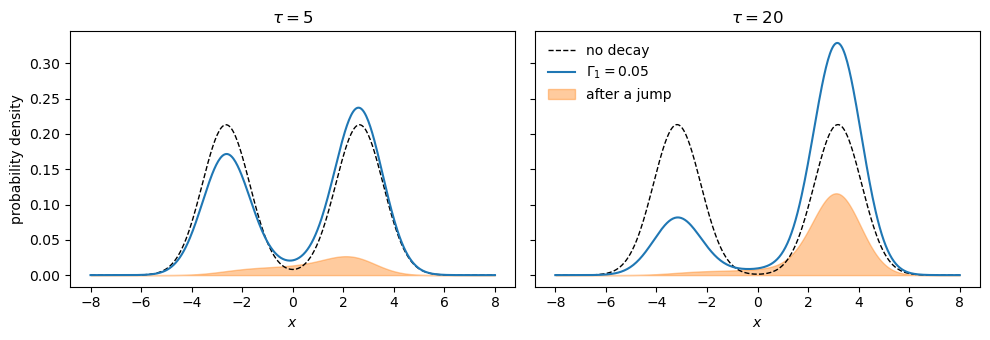

In [6]:
x = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, i in zip(axes, (i_5, i_20)):
    jumped = x_distribution(decay.perturbation_components[i], x)
    ax.plot(x, x_distribution(order_zero(ideal, i), x), 'k--', lw=1, label='no decay')
    ax.plot(x, x_distribution(order_zero(decay, i), x) + jumped, 'C0', label=r'$\Gamma_1 = 0.05$')
    ax.fill_between(x, jumped, color='C1', alpha=0.4, label='after a jump')
    ax.set_title(rf'$\tau = {tau1[i]:g}$')
    ax.set_xlabel('$x$')
axes[0].set_ylabel('probability density')
axes[1].legend(frameon=False)
plt.tight_layout()

The same split in phase space, at $\tau = 5$. On the left are the trajectories without a jump: the two pointer states, the excited one already depleted. On the right are those that jumped. Recent jumps are still close to the excited pointer state, and early ones have relaxed to the ground pointer state.

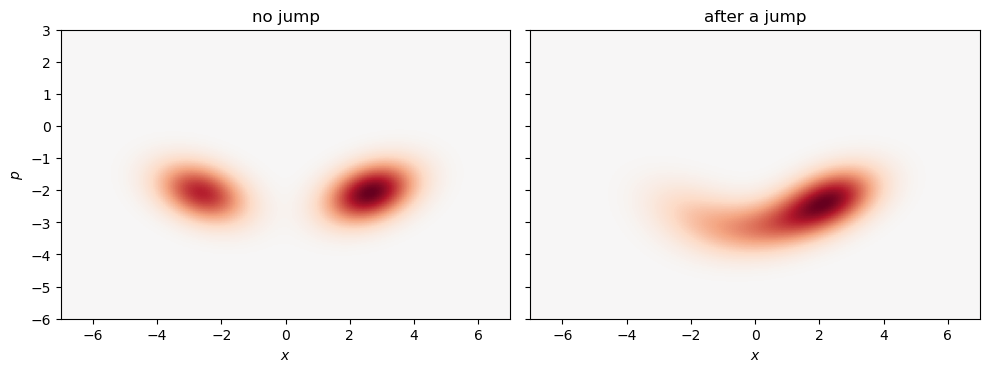

In [7]:
x, p = np.linspace(-7, 7, 181), np.linspace(-6, 3, 121)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
show_wigner(axes[0], wigner(order_zero(decay, i_5), x, p), x, p, 'no jump')
show_wigner(axes[1], wigner(decay.perturbation_components[i_5], x, p), x, p, 'after a jump')
axes[0].set_ylabel('$p$')
plt.tight_layout()

## Example 2: Stern–Gerlach interferometer

A qubit applies the force $f_q\hat\sigma_z$ to a trapped particle, which also feels an unknown force $f_u$ and position diffusion at rate $\Gamma_x$. In the notation of Table II this is $H_m = \mathbb{1}$ and $r_j = (f_u + j f_q,\,0)$. The particle starts in a squeezed thermal state and the qubit in $|+\rangle$. The parameters are those of Fig. 2 of the paper, with $\Gamma_2 = 0$.

In [8]:
f_q, f_u = 2.0, 0.5
N_p, s = 0.8, 0.5
Gamma_x, Gamma_1 = 0.05, 0.15

H2 = Hamiltonian(1, 1)
H2.Initialize_Constant_Hamiltonians([I2], [np.array([[f_u], [0.]]), np.array([[f_q], [0.]])], np.array([0.0]))
diffusion = Decoherence(1, 1, 'Canonical', Gamma_x*np.array([[1., 0.], [0., 0.]]))

tau2 = np.linspace(0, 2*np.pi, 201)
i_pi = 100


def interferometer(Gamma_1):
    T1 = Perturbation(N_qubits=1)
    T1.Add_T1([Gamma_1])
    G = Quantum_State(1, 1)
    G.Initialize_Gaussian_State(np.zeros((2, 1)), (1 + 2*N_p)*np.diag([s, 1/s]), np.ones((2, 2))/2)
    G.Perturbed_Dynamics(H2, T1, tau2, Decoherence=diffusion, order=1, store_times=[i_pi])
    return G


sg_ideal = interferometer(0.0)
sg_decay = interferometer(Gamma_1)

The contrast of a $\sigma_x$ measurement is $2|\varrho_{+-}| = e^{-\mathcal{C}}$. It vanishes while the wavepackets are apart and comes back when they recombine at $\tau = 2\pi$; diffusion keeps it from coming back fully. For one qubit a jump only feeds $\varrho_{--}$ and never restores coherence, so decay just multiplies the contrast by $e^{-\Gamma_1\tau/2}$. At recombination that is a factor $e^{-\pi\Gamma_1}$.

extra C at tau = 2 pi: 0.4712   (pi Gamma_1 = 0.4712)


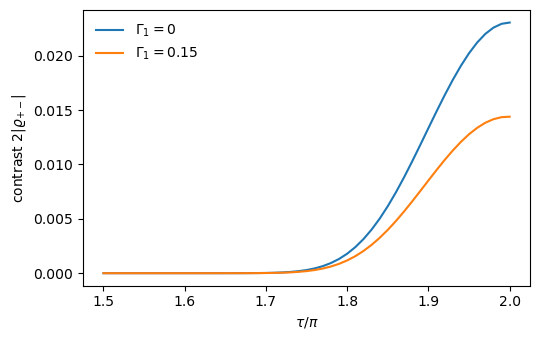

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
late = tau2 >= 1.5*np.pi
for G, label in ((sg_ideal, r'$\Gamma_1 = 0$'), (sg_decay, rf'$\Gamma_1 = {Gamma_1}$')):
    ax.plot(tau2[late]/np.pi, 2*np.abs(G.rho_q_t_total[late, 1, 0]), label=label)
ax.set_xlabel(r'$\tau/\pi$')
ax.set_ylabel(r'contrast $2|\varrho_{+-}|$')
ax.legend(frameon=False)
plt.tight_layout()

C_extra = -np.log(np.abs(sg_decay.rho_q_t_total[-1, 1, 0]/sg_ideal.rho_q_t_total[-1, 1, 0]))
print(f'extra C at tau = 2 pi: {C_extra:.4f}   (pi Gamma_1 = {np.pi*Gamma_1:.4f})')

At maximum separation, $\tau = \pi$, we measure $\sigma_x$ and keep the outcome $+1$. The mode is then left in $\mathcal{W}_+ = \mathrm{Tr}_q[\Pi_+\mathcal{W}]$. Its no-jump part is the two wavepackets with interference fringes between them. The jump part is $\mathcal{W}_\Gamma$ of the paper: particles whose qubit decayed at time $t$ followed the excited trajectory up to $t$ and the ground one after, so they are spread along an arc between the two wavepackets.

P(+) = 0.5000, of which 0.0939 comes from a jump


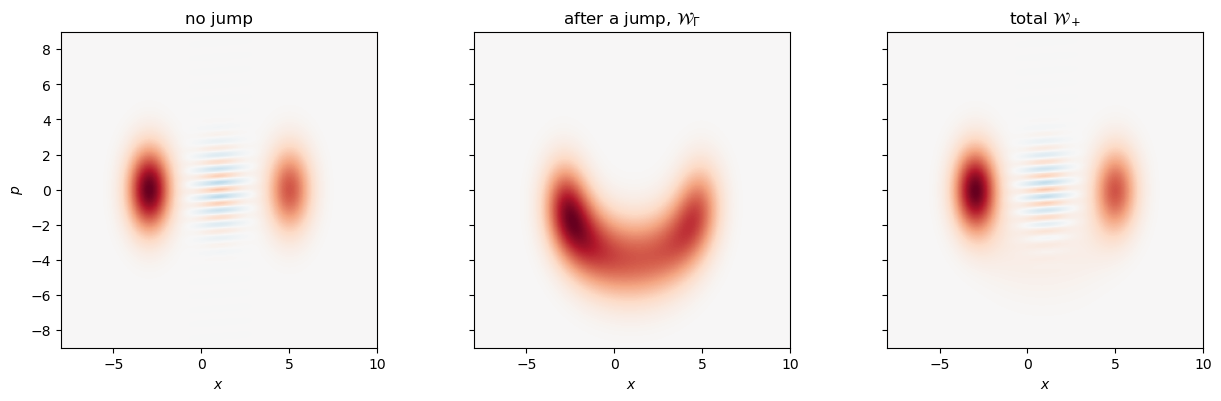

In [10]:
x, p = np.linspace(-8, 10, 241), np.linspace(-9, 9, 241)
no_jump = wigner(order_zero(sg_decay, i_pi), x, p, projector=PLUS)
jump = wigner(sg_decay.perturbation_components[i_pi], x, p, projector=PLUS)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
show_wigner(axes[0], no_jump, x, p, 'no jump')
show_wigner(axes[1], jump, x, p, r'after a jump, $\mathcal{W}_\Gamma$')
show_wigner(axes[2], no_jump + jump, x, p, r'total $\mathcal{W}_+$')
axes[0].set_ylabel('$p$')
plt.tight_layout()

area = (x[1] - x[0])*(p[1] - p[0])
print(f'P(+) = {area*np.sum(no_jump + jump):.4f}, of which {area*np.sum(jump):.4f} comes from a jump')

## Checks

Three properties of the result that can be checked without another solver:

- the ground population is $p_- + p_+(1 - e^{-\Gamma_1\tau})$; the jump times are integrated with the trapezoid rule, so the error falls as $\Delta\tau^2$;
- with one qubit, orders beyond the first vanish exactly;
- sampling the jump times (`method='monte_carlo'`) agrees with the quadrature within its standard error.

The comparison with a full Lindblad simulation in QuTiP, for drives and several qubits as well, is in `tests/test_perturbation.py`.

In [11]:
p_ground = 0.5 + 0.5*(1 - np.exp(-Gamma_1*tau2))
print('ground population, max error:', np.max(np.abs(sg_decay.rho_q_t_total[:, 0, 0] - p_ground)))

G = Quantum_State(1, 1)
G.Initialize_Gaussian_State(np.zeros((2, 1)), (1 + 2*N_p)*np.diag([s, 1/s]), np.ones((2, 2))/2)
T1 = Perturbation(N_qubits=1)
T1.Add_T1([Gamma_1])

G.Perturbed_Dynamics(H2, T1, tau2, Decoherence=diffusion, order=3)
print('largest element of orders 2 and 3:', np.max(np.abs(G.rho_q_t_orders[2:])))

G.Perturbed_Dynamics(H2, T1, tau2, Decoherence=diffusion, order=1, method='monte_carlo', n_samples=2000, seed=0)
error = np.abs(G.rho_q_t_orders[1, -1, 0, 0] - sg_decay.rho_q_t_orders[1, -1, 0, 0])
print(f'Monte Carlo at tau = 2 pi: off by {error:.1e}, standard error {G.rho_q_t_stderr[1, -1, 0, 0]:.1e}')

ground population, max error: 5.647313334744553e-07
largest element of orders 2 and 3: 0.0
Monte Carlo at tau = 2 pi: off by 9.1e-04, standard error 1.9e-03


## A drive on the qubit

A Rabi drive $\tfrac{\Omega}{2}\sigma_x$ also acts on the qubit alone, but its series does not stop: every order flips the qubit once more. We add it to the interferometer and watch the orders shrink. `perturbation_last_order` is the size of the last order computed, and the order should be raised until it is small. The drive here is $\Omega\tau \approx 0.6$ over the whole loop, so a few orders suffice.

In [12]:
Omega_R = 0.1
drive = Perturbation(N_qubits=1)
drive.Add_Hamiltonian(0.5*Omega_R*SIGMA_X)
drive.Add_T1([Gamma_1])

driven = Quantum_State(1, 1)
driven.Initialize_Gaussian_State(np.zeros((2, 1)), (1 + 2*N_p)*np.diag([s, 1/s]), np.ones((2, 2))/2)
tau_drive = np.linspace(0, 2*np.pi, 61)
for order in (1, 2, 3):
    driven.Perturbed_Dynamics(H2, drive, tau_drive, Decoherence=diffusion, order=order)
    print(f'order {order}: excited population at 2 pi = {driven.rho_q_t_total[-1, 1, 1].real:.5f}, '
          f'last order {driven.perturbation_last_order:.1e}')

order 1: excited population at 2 pi = 0.19475, last order 3.1e-01
order 2: excited population at 2 pi = 0.19548, last order 1.4e-03
order 3: excited population at 2 pi = 0.19576, last order 2.7e-04


The quadrature cost grows as $n_\tau^K$ with the order $K$. Monte Carlo sampling of the jump times scales better and gives a standard error with every order:

In [13]:
driven.Perturbed_Dynamics(H2, drive, tau_drive, Decoherence=diffusion, order=3, method='monte_carlo', n_samples=1000, seed=0)
print(f'Monte Carlo, order 3: excited population at 2 pi = {driven.rho_q_t_total[-1, 1, 1].real:.5f} '
      f'+- {np.sqrt(np.sum(driven.rho_q_t_stderr[:, -1, 1, 1]**2)):.1e}')

Monte Carlo, order 3: excited population at 2 pi = 0.19504 +- 1.7e-03


## Beyond one qubit

The same object covers the other cases of Sec. VII:

- `Perturbation(N_qubits=N).Add_T1([...])` decays each qubit of a register. The series stops after $N$ jumps, so use `order=N`.
- `Perturbation(N_levels=d).Add_Ladder_Decay([...])` decays a single $d$-level system down its ladder, with `Hamiltonian.Initialize_Qudit_Hamiltonians` for the levels.
- `Add_Hamiltonian(H_dv)` adds a qubit drive such as $\Omega\sigma_x$. Its series does not stop. `perturbation_last_order` gives the size of the last order computed, and the order should be raised until it is small.

The quadrature cost grows as $n_\tau^{K}$ with the order $K$. Above second or third order, `method='monte_carlo'` is the better choice.